# Лабораторна робота № 4. Advanced Net

Гліб Плахтій


## 1. Transformer для перекладу з англійської на українську

Використовуємо OPUS Tatoeba, версія `v2023-04-12`. Нормалізуємо Unicode й пробіли, зберігаємо регістр і пунктуацію. Залишаємо непорожні пари з максимум 16 англійськими та 20 українськими словами й прибираємо повтори. Після BPE обмежуємо послідовність 96 токенами разом із BOS та EOS. Групуємо пари за англійським реченням без урахування регістру, щоб варіанти його перекладу не перетинали межі вибірок. Відбираємо щонайбільше 22 000 пар і ділимо приблизно 80/10/10. Спільний BPE-словник навчаємо лише на train. [OPUS Tatoeba](https://opus.nlpl.eu/legacy/Tatoeba.php)

In [1]:
import gc
from collections import defaultdict
from importlib.metadata import version
from io import BytesIO
import os
from pathlib import Path
import random
import re
import shutil
import tarfile
import unicodedata
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from sacrebleu.metrics import CHRF
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import sentencepiece as spm
import torch
from torch import nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bf16 = DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()
DATA = Path("data")
DATA.mkdir(exist_ok=True)
os.environ.setdefault("HF_HOME", str((DATA / "huggingface").resolve()))
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "120")
print("Device:", DEVICE)
print({p: version(p) for p in ("torch", "transformers", "diffusers", "accelerate", "sentencepiece")})


def download(url, path):
    if not path.is_file():
        temporary = path.with_suffix(path.suffix + ".part")
        with urlopen(url, timeout=60) as response, temporary.open("wb") as file:
            shutil.copyfileobj(response, file)
        temporary.replace(path)
    return path


def release_memory():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

Device: cuda
{'torch': '2.8.0+cu129', 'transformers': '4.56.2', 'diffusers': '0.35.2', 'accelerate': '1.10.1', 'sentencepiece': '0.2.1'}


In [2]:
url = "https://object.pouta.csc.fi/OPUS-Tatoeba/v2023-04-12/moses/en-uk.txt.zip"
with ZipFile(download(url, DATA / "en-uk.txt.zip")) as archive:
    english = archive.read("Tatoeba.en-uk.en").decode("utf-8").splitlines()
    ukrainian = archive.read("Tatoeba.en-uk.uk").decode("utf-8").splitlines()
assert len(english) == len(ukrainian)


def clean_sentence(text):
    return " ".join(unicodedata.normalize("NFC", text).split())


pairs = pd.DataFrame({"English": list(map(clean_sentence, english)),
                      "Ukrainian": list(map(clean_sentence, ukrainian))})
keep = pairs["English"].str.split().str.len().between(1, 16) & pairs["Ukrainian"].str.split().str.len().between(1, 20)
pairs = pairs.loc[keep].drop_duplicates().reset_index(drop=True)
pairs = pairs.sample(n=min(22000, len(pairs)), random_state=SEED).reset_index(drop=True)
groups = pairs["English"].str.casefold()
train_idx, hold_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(pairs, groups=groups))
hold = pairs.iloc[hold_idx]
val_pos, test_pos = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED).split(
    hold, groups=hold["English"].str.casefold()))
translation_splits = {"Train": pairs.iloc[train_idx], "Validation": hold.iloc[val_pos], "Test": hold.iloc[test_pos]}
source_groups = [set(frame["English"].str.casefold()) for frame in translation_splits.values()]
assert sum(map(len, source_groups)) == len(set.union(*source_groups))
print({name: len(frame) for name, frame in translation_splits.items()})

PAD, BOS, EOS = 0, 1, 2
MAX_TOKENS = 96
train_pairs = translation_splits["Train"]
sp_file = BytesIO()
spm.SentencePieceTrainer.train(
    sentence_iterator=(text for row in train_pairs.itertuples(index=False, name=None) for text in row),
    model_writer=sp_file, model_type="bpe", vocab_size=6000, hard_vocab_limit=False,
    pad_id=PAD, bos_id=BOS, eos_id=EOS, unk_id=3, num_threads=1, shuffle_input_sentence=False,
)
sp = spm.SentencePieceProcessor(model_proto=sp_file.getvalue())
print("Vocabulary size:", sp.vocab_size())


def encode_translation(text):
    return [BOS, *sp.encode(text)[:MAX_TOKENS - 2], EOS]


def pair_loader(frame, training=False):
    items = [(encode_translation(en), encode_translation(uk))
             for en, uk in frame.itertuples(index=False, name=None)]

    def collate(batch):
        source, target = zip(*batch)
        return tuple(pad_sequence([torch.tensor(ids) for ids in side], batch_first=True,
                                  padding_value=PAD) for side in (source, target))

    return DataLoader(items, batch_size=96, collate_fn=collate, shuffle=training,
                      generator=torch.Generator().manual_seed(SEED))

{'Train': 17585, 'Validation': 2209, 'Test': 2206}
Vocabulary size: 6000


sentencepiece_trainer.cc(78) LOG(INFO) Starts training with : 
trainer_spec {
  input_format: 
  model_prefix: 
  model_type: BPE
  vocab_size: 6000
  self_test_sample_size: 0
  character_coverage: 0.9995
  input_sentence_size: 0
  shuffle_input_sentence: 0
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 1
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 0
  use_all_vocab: 0
  unk_id: 3
  bos_id: 1
  eos_id: 2
  pad_id: 0
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece: </s>
  pad_piece: <pad>
  unk_surface:  ⁇ 
  enable_differential_privacy: 0
  differential_privacy_noise_level: 0
  dif

280 all=10040 active=2854 piece=▁can
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=420 size=300 all=10520 active=3334 piece=ай
bpe_model_trainer.cc(159) LOG(INFO) Updating active symbols. max_freq=420 min_freq=86
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=376 size=320 all=11027 active=1446 piece=ion
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=345 size=340 all=11422 active=1841 piece=се
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=322 size=360 all=11839 active=2258 piece=ту
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=302 size=380 all=12090 active=2509 piece=да
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=280 size=400 all=12407 active=2826 piece=▁Мо
bpe_model_trainer.cc(159) LOG(INFO) Updating active symbols. max_freq=280 min_freq=76
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=258 size=420 all=12751 active=1332 piece=▁ку
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=247 size=440 all=12918 active=1499 piece=▁Why
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=23

iece=із
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=159 size=640 all=15816 active=1433 piece=ous
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=152 size=660 all=16029 active=1646 piece=▁О
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=149 size=680 all=16364 active=1981 piece=▁Where
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=143 size=700 all=16630 active=2247 piece=▁thought
bpe_model_trainer.cc(159) LOG(INFO) Updating active symbols. max_freq=142 min_freq=54
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=139 size=720 all=16902 active=1272 piece=▁ста
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=134 size=740 all=17147 active=1517 piece=ia
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=129 size=760 all=17391 active=1761 piece=ars
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=125 size=780 all=17595 active=1965 piece=▁much
bpe_model_trainer.cc(268) LOG(INFO) Added: freq=119 size=800 all=17794 active=2164 piece=▁Let
bpe_model_trainer.cc(159) LOG(INFO) Updating active symbols

### Архітектура і навчання

Два encoder-блоки й два decoder-блоки, розмірність 128, чотири голови, внутрішній шар FFN 256. Позиційне кодування синусоїдальне. Використовуємо residual connections, pre-norm і dropout 0,1. Увага в encoder та cross-attention пропускає PAD у джерелі. У decoder додатково приховуємо майбутні позиції. На вхід подаємо цільовий префікс, а прогноз зсуваємо на один токен. PAD виключено з loss. Бюджет - 12 епох, AdamW із learning rate 0,0005. Вибираємо стан з найменшим validation loss.

In [3]:
class Attention(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        self.heads = heads
        self.depth = width // heads
        self.query, self.key, self.value, self.output = [nn.Linear(width, width) for _ in range(4)]
        self.dropout = nn.Dropout(0.1)

    def split_heads(self, x):
        return x.reshape(x.size(0), x.size(1), self.heads, self.depth).transpose(1, 2)

    def forward(self, query, context, blocked):
        q, k, v = (self.split_heads(proj(x)) for proj, x in
                   ((self.query, query), (self.key, context), (self.value, context)))
        score = (q @ k.transpose(-2, -1)) / self.depth ** 0.5
        probability = score.masked_fill(blocked, float("-inf")).softmax(dim=-1)
        joined = (self.dropout(probability) @ v).transpose(1, 2).reshape_as(query)
        return self.output(joined)


class Block(nn.Module):
    def __init__(self, width, heads, decoder=False):
        super().__init__()
        self.self_attention = Attention(width, heads)
        self.cross_attention = Attention(width, heads) if decoder else None
        self.self_norm = nn.LayerNorm(width)
        self.cross_norm = nn.LayerNorm(width) if decoder else None
        self.ff_norm = nn.LayerNorm(width)
        self.ff = nn.Sequential(nn.Linear(width, 256), nn.GELU(), nn.Dropout(0.1), nn.Linear(256, width))
        self.dropout = nn.Dropout(0.1)

    def forward(self, x, self_mask, memory=None, memory_mask=None):
        normalized = self.self_norm(x)
        x = x + self.dropout(self.self_attention(normalized, normalized, self_mask))
        if self.cross_attention is not None:
            x = x + self.dropout(self.cross_attention(self.cross_norm(x), memory, memory_mask))
        return x + self.dropout(self.ff(self.ff_norm(x)))


def padding_mask(tokens):
    return tokens.eq(PAD)[:, None, None, :]


def decoder_mask(tokens):
    size = tokens.size(1)
    future = torch.ones(size, size, device=tokens.device, dtype=torch.bool).triu(1)
    return padding_mask(tokens) | future[None, None]


class TranslationNet(nn.Module):
    def __init__(self, vocabulary, max_length, width=128):
        super().__init__()
        self.embedding = nn.Embedding(vocabulary, width, padding_idx=PAD)
        self.width = width
        angles = torch.arange(max_length)[:, None] / 10000 ** (torch.arange(0, width, 2) / width)
        positions = torch.empty(max_length, width)
        positions[:, 0::2], positions[:, 1::2] = angles.sin(), angles.cos()
        self.register_buffer("positions", positions, persistent=False)
        self.encoder = nn.ModuleList(Block(width, 4) for _ in range(2))
        self.decoder = nn.ModuleList(Block(width, 4, decoder=True) for _ in range(2))
        self.encoder_norm, self.decoder_norm = nn.LayerNorm(width), nn.LayerNorm(width)
        self.output = nn.Linear(width, vocabulary)
        self.dropout = nn.Dropout(0.1)

    def embed(self, tokens):
        return self.dropout(self.embedding(tokens) * self.width ** 0.5 + self.positions[:tokens.size(1)])

    def encode(self, source, source_mask):
        x = self.embed(source)
        for block in self.encoder:
            x = block(x, source_mask)
        return self.encoder_norm(x)

    def decode(self, target, memory, source_mask):
        x, target_mask = self.embed(target), decoder_mask(target)
        for block in self.decoder:
            x = block(x, target_mask, memory, source_mask)
        return self.output(self.decoder_norm(x))

    def forward(self, source, target):
        source_mask = padding_mask(source)
        return self.decode(target, self.encode(source, source_mask), source_mask)

Causal masking, padding mask and target shift checks passed.


Epoch 01: train=6.1975, validation=5.3175


Epoch 02: train=5.0774, validation=4.9009


Epoch 03: train=4.7156, validation=4.6317


Epoch 04: train=4.4307, validation=4.4296


Epoch 05: train=4.1891, validation=4.2690


... (3 outputs left out)

Epoch 09: train=3.4467, validation=3.8093


Epoch 10: train=3.3162, validation=3.7402


Epoch 11: train=3.1927, validation=3.6874


Epoch 12: train=3.0783, validation=3.6295
Best epoch: 12; test token loss: 3.5999


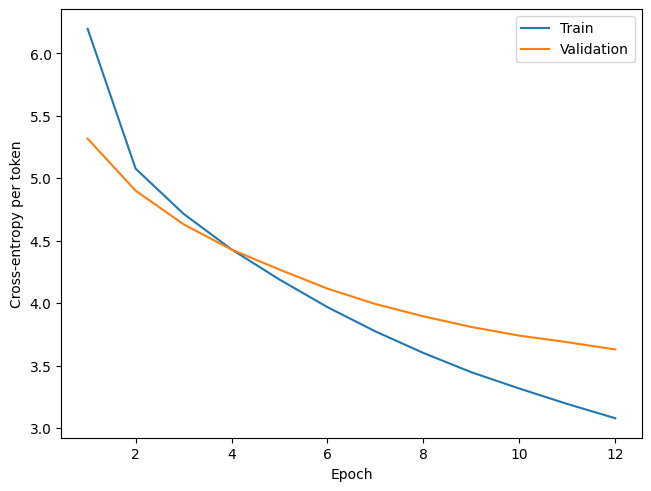

In [4]:
batches = {name: pair_loader(frame, training=name == "Train") for name, frame in translation_splits.items()}
net = TranslationNet(sp.vocab_size(), MAX_TOKENS).to(DEVICE)

example = torch.tensor([[BOS, 5, EOS, PAD]])
expected = [[False, True, True, True], [False, False, True, True],
            [False, False, False, True], [False, False, False, True]]
assert decoder_mask(example)[0, 0].tolist() == expected
assert padding_mask(example).flatten().tolist() == [False, False, False, True]
assert example[:, :-1].tolist() == [[BOS, 5, EOS]] and example[:, 1:].tolist() == [[5, EOS, PAD]]
net.eval()
with torch.inference_mode():
    inputs = torch.tensor([[BOS, 6, EOS, PAD], [BOS, 6, EOS, PAD]], device=DEVICE)
    prefix = torch.tensor([[BOS, 7, 8], [BOS, 7, 9]], device=DEVICE)
    torch.testing.assert_close(net(inputs, prefix)[0, :2], net(inputs, prefix)[1, :2])
print("Causal masking, padding mask and target shift checks passed.")

optimizer = torch.optim.AdamW(net.parameters(), lr=5e-4)
loss_fn = nn.CrossEntropyLoss(ignore_index=PAD, reduction="sum")


def translation_epoch(loader, training):
    net.train(training)
    total_loss = total_tokens = 0
    with torch.set_grad_enabled(training):
        for source, target in loader:
            source, target = source.to(DEVICE), target.to(DEVICE)
            decoder_input, gold = target[:, :-1], target[:, 1:]
            tokens = gold.ne(PAD).sum()
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=bf16):
                scores = net(source, decoder_input)
                loss = loss_fn(scores.flatten(0, 1), gold.reshape(-1))
            if training:
                (loss / tokens).backward()
                nn.utils.clip_grad_norm_(net.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item()
            total_tokens += tokens.item()
    return total_loss / total_tokens


history = []
best_loss = float("inf")
checkpoint = DATA / "translation_model.pt"
for epoch in range(1, 13):
    train_loss = translation_epoch(batches["Train"], True)
    val_loss = translation_epoch(batches["Validation"], False)
    history.append((train_loss, val_loss))
    if val_loss < best_loss:
        best_loss, best_epoch = val_loss, epoch
        torch.save(net.state_dict(), checkpoint)
    print(f"Epoch {epoch:02d}: train={train_loss:.4f}, validation={val_loss:.4f}")
net.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
print(f"Best epoch: {best_epoch}; test token loss: {translation_epoch(batches['Test'], False):.4f}")
fig, ax = plt.subplots(layout="constrained")
ax.plot(range(1, len(history) + 1), history, label=["Train", "Validation"])
ax.set(xlabel="Epoch", ylabel="Cross-entropy per token")
ax.legend()
plt.show()

In [5]:
@torch.inference_mode()
def translate_batch(sentences):
    net.eval()
    source = pad_sequence([torch.tensor(encode_translation(text)) for text in sentences],
                          batch_first=True, padding_value=PAD).to(DEVICE)
    mask = padding_mask(source)
    memory = net.encode(source, mask)
    target = torch.full((len(sentences), 1), BOS, device=DEVICE)
    done = torch.zeros(len(sentences), dtype=torch.bool, device=DEVICE)
    for _ in range(56):
        logits = net.decode(target, memory, mask)[:, -1, :]
        logits[:, [PAD, BOS]] = float("-inf")
        token = logits.argmax(dim=-1).masked_fill(done, EOS)
        target = torch.cat([target, token[:, None]], dim=1)
        done |= token.eq(EOS)
        if done.all():
            break
    return [sp.decode(ids[1:ids.index(EOS)] if EOS in ids else ids[1:]) for ids in target.cpu().tolist()]


sample = translation_splits["Test"].sample(n=min(240, len(translation_splits["Test"])), random_state=SEED).copy()
sample["Prediction"] = [text for start in range(0, len(sample), 32)
                        for text in translate_batch(sample["English"].iloc[start:start + 32])]
metric = CHRF()
print("Test subset chrF:",
      round(metric.corpus_score(sample["Prediction"].tolist(), [sample["Ukrainian"].tolist()]).score, 2))
sentence_scores = [metric.sentence_score(prediction, [reference]).score
                   for prediction, reference in zip(sample["Prediction"], sample["Ukrainian"])]
sample["chrF"] = np.round(sentence_scores, 1)
display(sample.head(6))
display(sample.nsmallest(3, "chrF"))
del net, optimizer
release_memory()

Test subset chrF: 17.18


,English,Ukrainian,Prediction,chrF
16996,Tom is likely to win the race.,"Цілком імовірно, що Том виграє перегони.","Том має бути добрим, щоб піти.",12.8
16004,Would you please hold on a second?,Ти не могла би секунду зачекати?,Ти не міг би бути добрим?,17.5
14856,Tom wanted to see Wales.,Том хотів побачити Уельс.,Том хотів бути добрим батьком.,34.7
4259,Who's the fastest one here?,Хто тут найшвидший?,Хто тут тут у світі?,25.4
17874,Sami doesn't doubt that.,Самі не має сумнівів щодо цього.,"Стайся, що це не має рації.",16.6
18821,I am fascinated by palindromes.,Паліндроми мене зачаровують.,Я погв'я.,2.2


,English,Ukrainian,Prediction,chrF
4207,The party's over.,Вечірка закінчилася.,Стовець.,2.0
21893,The party's over.,Вечірка скінчилася.,Стовець.,2.1
18821,I am fascinated by palindromes.,Паліндроми мене зачаровують.,Я погв'я.,2.2


На 240 відкладених реченнях Transformer отримав chrF **17,18**. Найнижчий validation loss (3,6295) був на 12-й епосі, test loss становив 3,5999 на токен. Модель іноді зберігає початок речення, але змінює його зміст. Наприклад, у реченні про Уельс з’явився батько, а в перекладі питання про найшвидшу людину зникла ознака швидкості. Є повтори слів і вигадані форми. Якість цього експерименту низька навіть для коротких речень Tatoeba. Декодування жадібне й обмежене 56 новими токенами.

## 2а. Текстові pipeline Hugging Face

У першому прикладі багатомовна mDeBERTa оцінює три гіпотези про тему українського тексту. Це zero-shot перенесення на українську. mT5 навчено на XL-Sum, до якого входить українська. Для резюме перевіряємо ключовий факт про 12 велосипедів і дату відкриття. MarianMT має фіксовану пару `uk` → `en`, тому напрям задано самим checkpoint. [mDeBERTa](https://huggingface.co/MoritzLaurer/mDeBERTa-v3-base-mnli-xnli) · [mT5 XL-Sum](https://huggingface.co/csebuetnlp/mT5_multilingual_XLSum) · [MarianMT](https://huggingface.co/Helsinki-NLP/opus-mt-uk-en)

In [6]:
from transformers import pipeline

hf_device = 0 if DEVICE.type == "cuda" else -1
zero_id = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
zero_input = "Міська рада відкрила майстерню, де волонтери ремонтують покинуті велосипеди."
topic = pipeline("zero-shot-classification", model=zero_id, use_fast=False, device=hf_device,
                 revision="8adb042d524ecd5c26d3e3ba0e3fbcf7e2d0864c")
scores = topic(zero_input, candidate_labels=["міський транспорт", "медицина", "театр"],
               hypothesis_template="Цей текст про {}.")
print("Model:", zero_id)
print("Input:", zero_input)
display(pd.DataFrame({"Label": scores["labels"], "Score": scores["scores"]}).round(4))
del topic
release_memory()

sum_id = "csebuetnlp/mT5_multilingual_XLSum"
sum_input = ("У суботу, 5 грудня, міська рада відкриє у бібліотеці пункт безоплатного прокату "
             "12 велосипедів. Для реєстрації потрібен читацький квиток. Волонтери перевірятимуть "
             "технічний стан велосипедів після кожного повернення.")
summarizer = pipeline("summarization", model=sum_id, device=hf_device, use_fast=False,
                      model_kwargs={"use_safetensors": False},
                      revision="2437a524effdbadc327ced84595508f1e32025b3")
summary = summarizer(sum_input, max_new_tokens=65, num_beams=4, do_sample=False)[0]["summary_text"]
print("Model:", sum_id)
print("Input:", sum_input)
print("Summary:", summary)
print("Reference facts:", ["free bicycle lending", "12 bicycles", "5 December"])
print("Explicit quantity 12:", bool(re.search(r"\b12\b|дванадцять", summary, re.IGNORECASE)))
print("Explicit date 5 December:", bool(re.search(r"(?:\b5\b|п['’]ятого) грудня", summary, re.IGNORECASE)))
del summarizer
release_memory()

translator_id = "Helsinki-NLP/opus-mt-uk-en"
translation_input = "Наступного тижня волонтери перевірять велосипеди після ремонту."
translator = pipeline("translation", model=translator_id, device=hf_device,
                      model_kwargs={"use_safetensors": False},
                      revision="1b9a2a0d1aa2a329d8476d2be5c7b0b27d5397b0")
print("Model:", translator_id)
print("Direction: uk -> en")
print("Input:", translation_input)
print("Translation:", translator(translation_input, max_new_tokens=90)[0]["translation_text"])
del translator
release_memory()

Device set to use cuda:0


Model: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli
Input: Міська рада відкрила майстерню, де волонтери ремонтують покинуті велосипеди.


,Label,Score
0,міський транспорт,0.9980
1,театр,0.0011
2,медицина,0.0008


model.safetensors:   5%|4         | 115M/2.33G [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


Device set to use cuda:0


Your max_length is set to 84, but your input_length is only 64. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=32)


Model: csebuetnlp/mT5_multilingual_XLSum
Input: У суботу, 5 грудня, міська рада відкриє у бібліотеці пункт безоплатного прокату 12 велосипедів. Для реєстрації потрібен читацький квиток. Волонтери перевірятимуть технічний стан велосипедів після кожного повернення.
Summary: У Києві відкрили пункт безоплатного прокату велосипедів.
Reference facts: ['free bicycle lending', '12 bicycles', '5 December']
Explicit quantity 12: False
Explicit date 5 December: False


Device set to use cuda:0


Model: Helsinki-NLP/opus-mt-uk-en
Direction: uk -> en
Input: Наступного тижня волонтери перевірять велосипеди після ремонту.
Translation: The next week, volunteers will check the bike after the repairs.


У zero-shot прикладі найбільшу оцінку (0,9980) отримала мітка «міський транспорт». Резюме зберегло факт безоплатного прокату велосипедів, але пропустило дату й кількість, додало відсутній у джерелі Київ і подало майбутню подію як завершену. MarianMT передав дію й час, але переклав множину «велосипеди» одниною `the bike`.

## 2б. DistilBERT на SMS Spam Collection

Відтворюємо порядок рядків, нормалізацію, видалення конфліктних міток і дублікатів та стратифікований test із seed 42 з Lab 2. Для перевірки повторно навчаємо оригінальний TF-IDF + LogisticRegression на повному train і звіряємо матрицю зі збереженою. Для DistilBERT із того самого train відділяємо 15% на validation. Порівняння використовує однаковий test, але DistilBERT навчається на меншій частині train.

DistilBERT використовує англомовний uncased checkpoint і максимум 96 токенів. Усі параметри донавчаємо дві епохи, batch size 32, AdamW із learning rate 0,00002. Обираємо checkpoint за validation macro F1. Порівнюємо accuracy, macro F1, precision і recall за класами та напрямки помилок. [SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) · [Lab 2](../lab%202/lab2_dimensionality_clustering_text.ipynb) · [DistilBERT](https://huggingface.co/distilbert/distilbert-base-uncased)

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding
from transformers import Trainer, TrainingArguments

SMS_LABELS = ["ham", "spam"]
sms_url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
sms_local = Path("../lab 2/data/SMSSpamCollection")
if sms_local.is_file():
    raw_sms = sms_local.read_text(encoding="utf-8")
else:
    with ZipFile(download(sms_url, DATA / "sms_spam_collection.zip")) as archive:
        raw_sms = archive.read("SMSSpamCollection").decode("utf-8")


def normalize_sms(message):
    normalized = unicodedata.normalize("NFKC", message).casefold()
    return " ".join(re.findall(r"[^\W_]{2,}", normalized))


sms = pd.DataFrame([line.split("\t", 1) for line in raw_sms.splitlines()], columns=["label", "text"])
sms = sms.dropna(subset=["label", "text"]).copy()
sms["normalized"] = sms["text"].map(normalize_sms)
sms = sms.loc[sms["normalized"].ne("")].copy()
label_counts = sms.groupby("normalized")["label"].nunique()
conflicts = sms["normalized"].isin(label_counts[label_counts > 1].index)
sms = sms.loc[~conflicts].drop_duplicates("normalized")
x_train, x_test, y_train, y_test = train_test_split(
    sms["normalized"], sms["label"], test_size=0.2, stratify=sms["label"], random_state=SEED)
x_fit, x_val, y_fit, y_val = train_test_split(
    x_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED)
assert set(x_train).isdisjoint(x_test) and set(x_fit).isdisjoint(x_val)
assert y_test.value_counts().to_dict() == {"ham": 899, "spam": 126}
display(pd.DataFrame({"Train": y_fit.value_counts(), "Validation": y_val.value_counts(),
                      "Test": y_test.value_counts()}).loc[SMS_LABELS])

baseline = make_pipeline(
    TfidfVectorizer(lowercase=False, ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
)
lab2_prediction = baseline.fit(x_train, y_train).predict(x_test)
lab2_matrix = confusion_matrix(y_test, lab2_prediction, labels=SMS_LABELS)
assert np.array_equal(lab2_matrix,
                      [[891, 8], [11, 115]]), "The reproduced Lab 2 matrix does not match the saved result."
print("Lab 2 test support and baseline confusion matrix match the saved outputs.")

,Train,Validation,Test
label,,,
ham,3057,540,899
spam,428,75,126


Lab 2 test support and baseline confusion matrix match the saved outputs.


In [8]:
model_id = "distilbert/distilbert-base-uncased"
revision = "12040accade4e8a0f71eabdb258fecc2e7e948be"
torch.manual_seed(SEED)
tokenizer = AutoTokenizer.from_pretrained(model_id, revision=revision)
label_ids = {label: i for i, label in enumerate(SMS_LABELS)}
classifier = AutoModelForSequenceClassification.from_pretrained(
    model_id, revision=revision, num_labels=2, label2id=label_ids, id2label=dict(enumerate(SMS_LABELS)))
print("Model:", model_id)
print("Trainable parameters:", sum(p.numel() for p in classifier.parameters() if p.requires_grad))


def examples(text, labels):
    encodings = tokenizer(text.tolist(), truncation=True, max_length=96)
    return [
        {**{name: values[i] for name, values in encodings.items()}, "labels": label_ids[label]}
        for i, label in enumerate(labels)
    ]


def sms_metrics(prediction):
    actual = prediction.label_ids
    predicted = prediction.predictions.argmax(axis=1)
    report = classification_report(actual, predicted, labels=[0, 1], output_dict=True, zero_division=0)
    return {"macro_f1": report["macro avg"]["f1-score"]}


args = TrainingArguments(
    output_dir=str(DATA / "distilbert_sms"), learning_rate=2e-5,
    per_device_train_batch_size=32, per_device_eval_batch_size=64, num_train_epochs=2,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
    bf16=bf16, seed=SEED, data_seed=SEED, report_to="none", logging_strategy="epoch",
)
trainer = Trainer(
    model=classifier, args=args, train_dataset=examples(x_fit, y_fit),
    eval_dataset=examples(x_val, y_val), data_collator=DataCollatorWithPadding(tokenizer),
    processing_class=tokenizer, compute_metrics=sms_metrics,
)
trainer.train()
print("Selected validation macro F1:", round(trainer.state.best_metric, 4))
test_scores = trainer.predict(examples(x_test, y_test)).predictions
hf_prediction = np.asarray(SMS_LABELS)[test_scores.argmax(axis=1)]


def sms_row(prediction):
    report = classification_report(y_test, prediction, labels=SMS_LABELS, output_dict=True, zero_division=0)
    matrix = confusion_matrix(y_test, prediction, labels=SMS_LABELS)
    return {"Accuracy": accuracy_score(y_test, prediction), "Macro F1": report["macro avg"]["f1-score"],
            **{f"{label} {metric}": report[label][metric] for label in SMS_LABELS for metric in
               ("precision", "recall")},
            "False alarms": matrix[0, 1], "Missed spam": matrix[1, 0]}


comparison = pd.DataFrame(
    [sms_row(lab2_prediction), sms_row(hf_prediction)], index=["Lab 2 TF-IDF + LogisticRegression", "DistilBERT"])
comparison.loc["DistilBERT minus Lab 2"] = comparison.iloc[1] - comparison.iloc[0]
display(comparison.round(4))
hf_matrix = confusion_matrix(y_test, hf_prediction, labels=SMS_LABELS)
for name, matrix in [("Lab 2", lab2_matrix), ("DistilBERT", hf_matrix)]:
    print(name)
    display(pd.DataFrame(matrix, index=pd.Index(SMS_LABELS, name="Actual"),
                         columns=pd.Index(SMS_LABELS, name="Prediction")))
print(f"Macro F1 change: {comparison.loc['DistilBERT minus Lab 2', 'Macro F1']:+.4f}")
del trainer, classifier
release_memory()

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model: distilbert/distilbert-base-uncased
Trainable parameters: 66955010


Epoch,Training Loss,Validation Loss,Macro F1
1,0.136300,0.057736,0.953914
2,0.033400,0.055638,0.957999


model.safetensors:  21%|##        | 62.9M/305M [00:00<?, ?B/s]

Selected validation macro F1: 0.958


,Accuracy,Macro F1,ham precision,ham recall,spam precision,spam recall,False alarms,Missed spam
Lab 2 TF-IDF + LogisticRegression,0.9815,0.9566,0.9878,0.9911,0.935,0.9127,8.0,11.0
DistilBERT,0.9854,0.9660,0.9911,0.9922,0.944,0.9365,7.0,8.0
DistilBERT minus Lab 2,0.0039,0.0094,0.0033,0.0011,0.009,0.0238,-1.0,-3.0


Lab 2


Prediction,ham,spam
Actual,,
ham,891,8
spam,11,115


DistilBERT


Prediction,ham,spam
Actual,,
ham,892,7
spam,8,118


Macro F1 change: +0.0094


На тих самих 1 025 SMS DistilBERT підвищив macro F1 із **0,9566 до 0,9660** (+0,0094), а accuracy - із 98,15% до 98,54%. Модель пропустила 8 спам-повідомлень проти 11 у TF-IDF, а звичайних повідомлень помилково заблокувала 7 проти 8. Основна зміна - повнота класу `spam` зросла з 91,27% до 93,65%. Це результат одного поділу. DistilBERT використовував pretrained ваги та меншу навчальну вибірку через окремий validation.

## 3а. Генерація зображення в Diffusers

Використовуємо text-to-image SD-Turbo. Ширина та висота - 512, чотири кроки denoising, guidance scale 0 і seed 42. На GPU використовуємо FP16. [SD-Turbo](https://huggingface.co/stabilityai/sd-turbo)

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Model: stabilityai/sd-turbo
Prompt: An editorial photograph of a miniature Kyiv tram made from folded blue paper, crossing a bridge built from old library cards, warm morning light, handmade diorama
{'seed': 42, 'steps': 4, 'width': 512, 'height': 512, 'guidance_scale': 0.0}


  0%|          | 0/4 [00:00<?, ?it/s]

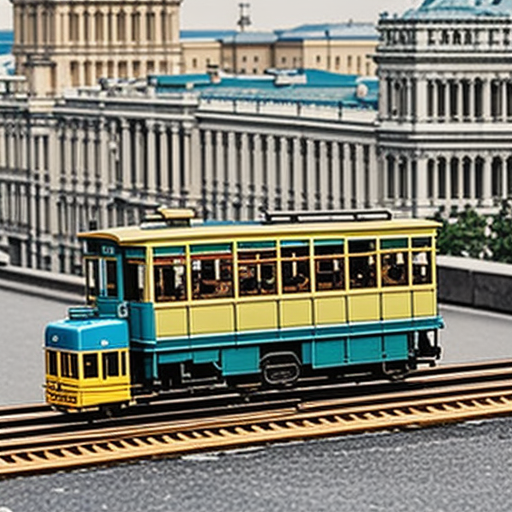

In [9]:
from diffusers import AutoPipelineForText2Image

diffusion_id = "stabilityai/sd-turbo"
prompt = ("An editorial photograph of a miniature Kyiv tram made from folded blue paper, "
          "crossing a bridge built from old library cards, warm morning light, handmade diorama")
options = {"torch_dtype": torch.float16, "variant": "fp16"} if DEVICE.type == "cuda" else {"torch_dtype": torch.float32}
generator = torch.Generator(device=DEVICE).manual_seed(SEED)
image_pipeline = AutoPipelineForText2Image.from_pretrained(
    diffusion_id, revision="b261bac6fd2cf515557d5d0707481eafa0485ec2", **options).to(DEVICE)
print("Model:", diffusion_id)
print("Prompt:", prompt)
print({"seed": SEED, "steps": 4, "width": 512, "height": 512, "guidance_scale": 0.0})
with torch.inference_mode():
    generated = image_pipeline(prompt, num_inference_steps=4, guidance_scale=0.0, width=512,
                               height=512, generator=generator).images[0]
display(generated)
del image_pipeline
release_memory()

SD-Turbo відтворив трамвай на мосту та контрастні кольори. Трамвай виглядає як детальна модель, але складки паперу та бібліотечні картки в мосту не розпізнаються. Генерація краще передала загальну сцену, ніж матеріали з prompt.

## 3б. Порівняння фото через DINOv2

Беремо десять різних фотографій із Oxford 17 Flowers, по дві з п’яти видів. Ідентифікатори відповідають номерам файлів. Processor масштабує, кадрує й нормує їх відповідно до налаштувань DINOv2. Вектор зображення - фінальний CLS-токен розмірності 384. Кожен вектор L2-нормуємо. Відстань порівнює вектори навченої моделі та може відображати колір, форму й фон. [Oxford 17 Flowers](https://www.robots.ox.ac.uk/~vgg/data/flowers/17/) · [DINOv2 Small](https://huggingface.co/facebook/dinov2-small)

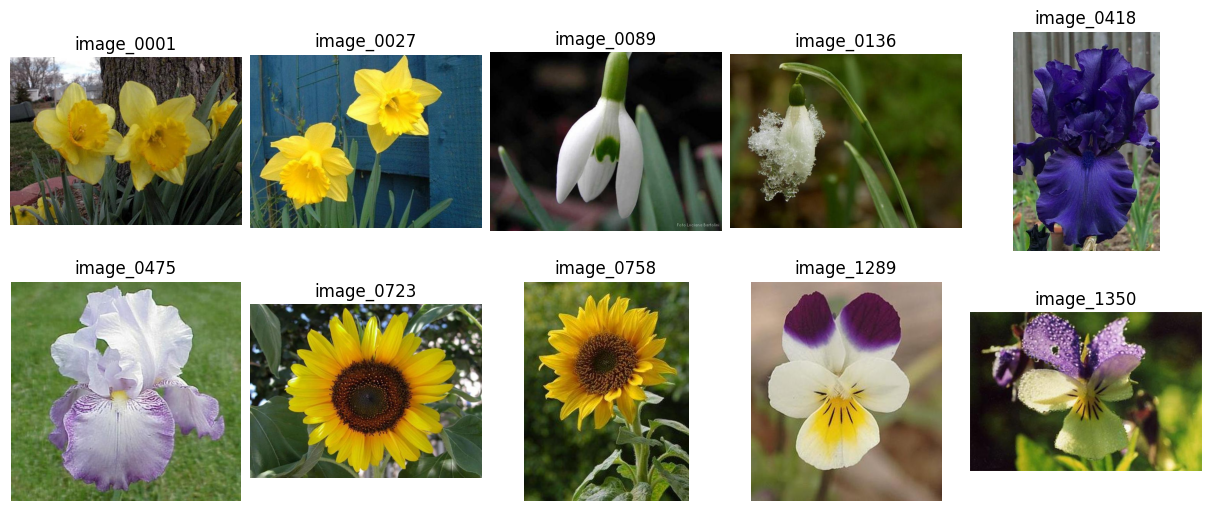

Model: facebook/dinov2-small
Embedding dimension: 384
L2 norms: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


,image_0001,image_0027,image_0089,image_0136,image_0418,image_0475,image_0723,image_0758,image_1289,image_1350
image_0001,0.0000,0.5217,1.2584,1.2657,1.2687,1.2756,1.3433,1.3068,1.2555,1.3506
image_0027,0.5217,0.0000,1.2591,1.2989,1.2968,1.2681,1.3333,1.2776,1.2039,1.3268
image_0089,1.2584,1.2591,0.0000,1.0112,1.4506,1.4336,1.3961,1.4193,1.3157,1.4089
image_0136,1.2657,1.2989,1.0112,0.0000,1.3787,1.3378,1.3967,1.4155,1.3772,1.3672
image_0418,1.2687,1.2968,1.4506,1.3787,0.0000,0.6708,1.4123,1.4477,1.2166,1.2187
image_0475,1.2756,1.2681,1.4336,1.3378,0.6708,0.0000,1.3859,1.4398,1.0654,1.1325
image_0723,1.3433,1.3333,1.3961,1.3967,1.4123,1.3859,0.0000,0.6025,1.4224,1.4762
image_0758,1.3068,1.2776,1.4193,1.4155,1.4477,1.4398,0.6025,0.0000,1.4409,1.4754
image_1289,1.2555,1.2039,1.3157,1.3772,1.2166,1.0654,1.4224,1.4409,0.0000,0.7627
image_1350,1.3506,1.3268,1.4089,1.3672,1.2187,1.1325,1.4762,1.4754,0.7627,0.0000


Nearest: image_0001, image_0027; distance=0.5217
Farthest: image_0723, image_1350; distance=1.4762


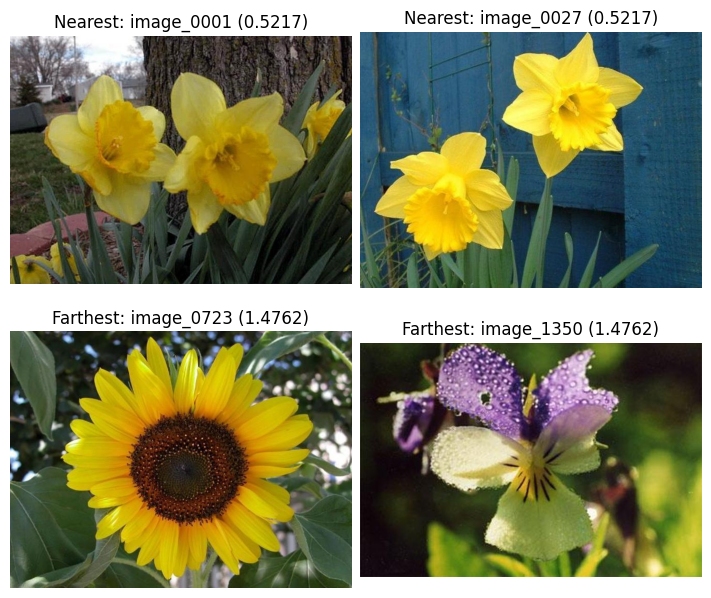

In [10]:
from transformers import AutoImageProcessor, AutoModel

image_ids = [1, 27, 89, 136, 418, 475, 723, 758, 1289, 1350]
archive_path = Path("../lab 3/data/17flowers.tgz")
if not archive_path.is_file():
    archive_path = download("https://www.robots.ox.ac.uk/~vgg/data/flowers/17/17flowers.tgz",
                            DATA / "17flowers.tgz")
files = {f"image_{i:04d}.jpg": f"image_{i:04d}" for i in image_ids}
flower_images = {}
with tarfile.open(archive_path, "r:gz") as archive:
    for member in archive:
        filename = Path(member.name).name
        if member.isfile() and filename in files:
            with archive.extractfile(member) as blob, Image.open(BytesIO(blob.read())) as image:
                flower_images[files[filename]] = image.convert("RGB")
names = list(files.values())
assert set(names) == set(flower_images) and len(names) == 10
images = [flower_images[name] for name in names]

fig, axes = plt.subplots(2, 5, figsize=(12, 5), layout="constrained")
for ax, name, image in zip(axes.flat, names, images):
    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")
plt.show()

dino_id, dino_revision = "facebook/dinov2-small", "ed25f3a31f01632728cabb09d1542f84ab7b0056"
processor = AutoImageProcessor.from_pretrained(dino_id, revision=dino_revision, use_fast=False)
dino = AutoModel.from_pretrained(dino_id, revision=dino_revision).to(DEVICE).eval()
with torch.inference_mode():
    pixels = processor(images=images, return_tensors="pt").to(DEVICE)
    embeddings = F.normalize(dino(**pixels).last_hidden_state[:, 0, :].float(), p=2, dim=1)
    norms = embeddings.norm(dim=1).cpu()
    distances = torch.cdist(embeddings, embeddings, compute_mode="donot_use_mm_for_euclid_dist").cpu().numpy()
torch.testing.assert_close(norms, torch.ones_like(norms))
assert np.allclose(distances, distances.T) and np.allclose(distances.diagonal(), 0)
i, j = np.triu_indices(len(names), k=1)
values = distances[i, j]
assert len(values) == 45
print("Model:", dino_id)
print("Embedding dimension:", embeddings.shape[1])
print("L2 norms:", norms.numpy().round(6))
display(pd.DataFrame(distances, index=names, columns=names).round(4))

fig, axes = plt.subplots(2, 2, figsize=(7, 6), layout="constrained")
for ax_row, title, index in zip(axes, ["Nearest", "Farthest"], [values.argmin(), values.argmax()]):
    distance = values[index]
    pair = [i[index], j[index]]
    print(f"{title}: {names[pair[0]]}, {names[pair[1]]}; distance={distance:.4f}")
    for ax, pos in zip(ax_row, pair):
        ax.imshow(images[pos])
        ax.set_title(f"{title}: {names[pos]} ({distance:.4f})")
        ax.axis("off")
plt.show()
del dino
release_memory()

Найближча пара - `image_0001` та `image_0027` (0,5217). На обох фото жовті нарциси зі схожою формою пелюсток, хоча фон різний. Найдальша пара - `image_0723` та `image_1350` (1,4762). Соняшник має великий круглий центр і багато жовтих пелюсток. У браток інша форма, менше пелюсток і жовто-фіолетове забарвлення. Для цих крайніх пар відстані узгоджуються з видимою подібністю.